### Explainable Credit Risk Assessment

#### 1. Load the Data
- We will bring in the loan applicant data.
- This data has details like income, age, and loan amount.
- It also tells us who repaid and who defaulted.

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


#### 2. Exploratory Data Analysis (EDA)
- Here we simply look at the data before touching it.
- We want to understand it first, then work on it.
##### Basic info about the data
- Check how many rows and columns we have.
- Check the data type of each column.

In [67]:
df.shape

(32581, 12)

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB


##### Missing values
- Find out which columns have empty or missing values.
- This tells us where we may need to fix things later.

In [69]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

#### Target balance
- Check how many people defaulted vs how many repaid.
- This tells us if our data is balanced or imbalanced.

In [70]:
display(df['loan_status'].value_counts().to_frame(name='Count'))

,Count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

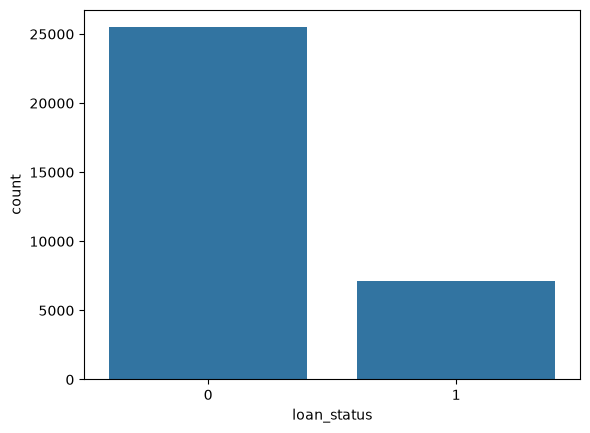

In [71]:
sns.countplot(x='loan_status',data=df)

#### Outlier check

- Look for values that seems to be impossible, like age 144.
- These are the signs of bad data entries

In [72]:
df.describe().T 

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


In [73]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
numerical_cols

['person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_status',
 'loan_percent_income',
 'cb_person_cred_hist_length']

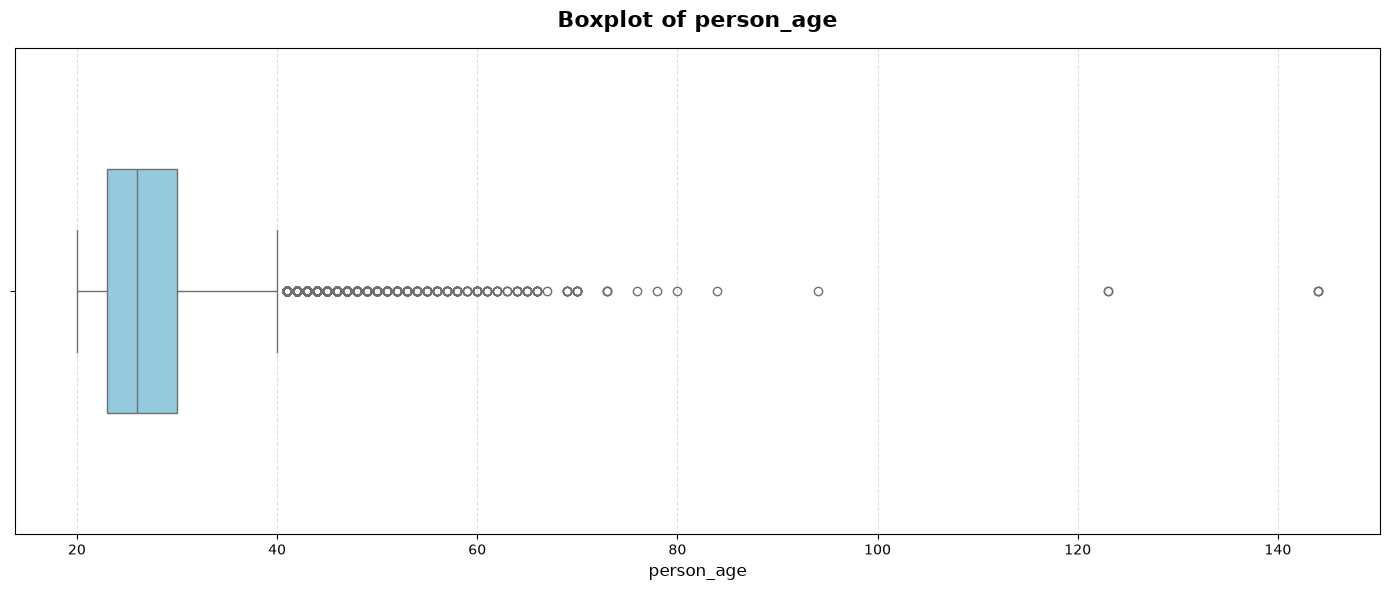

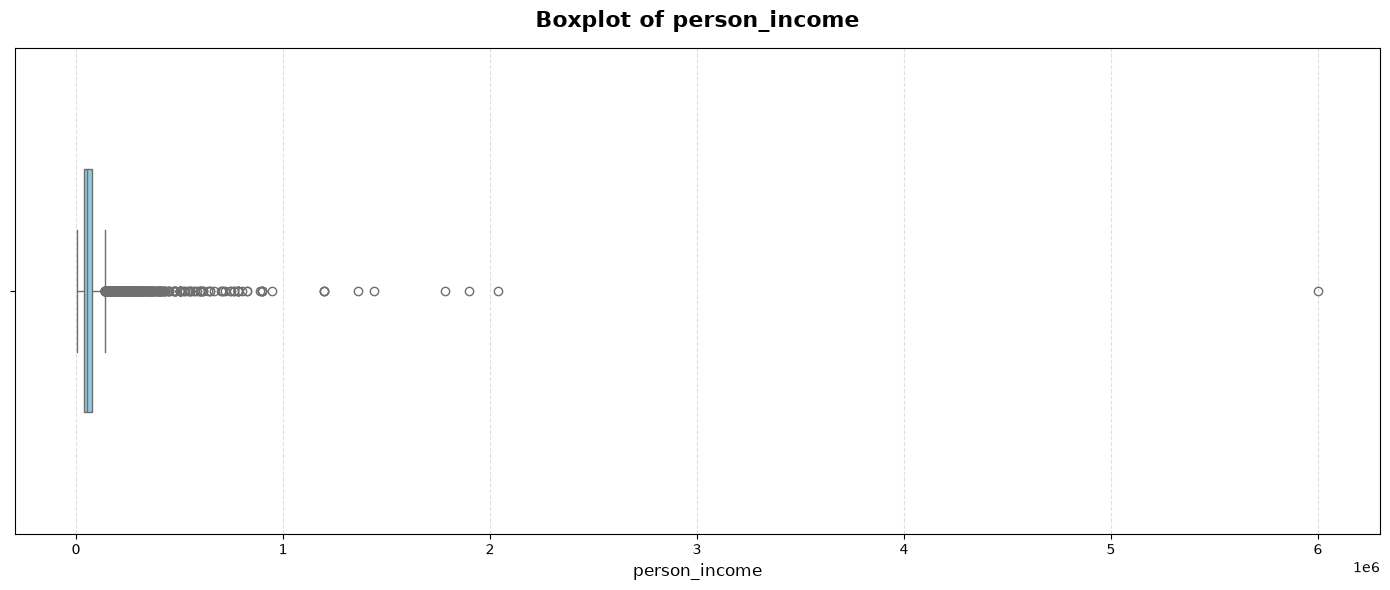

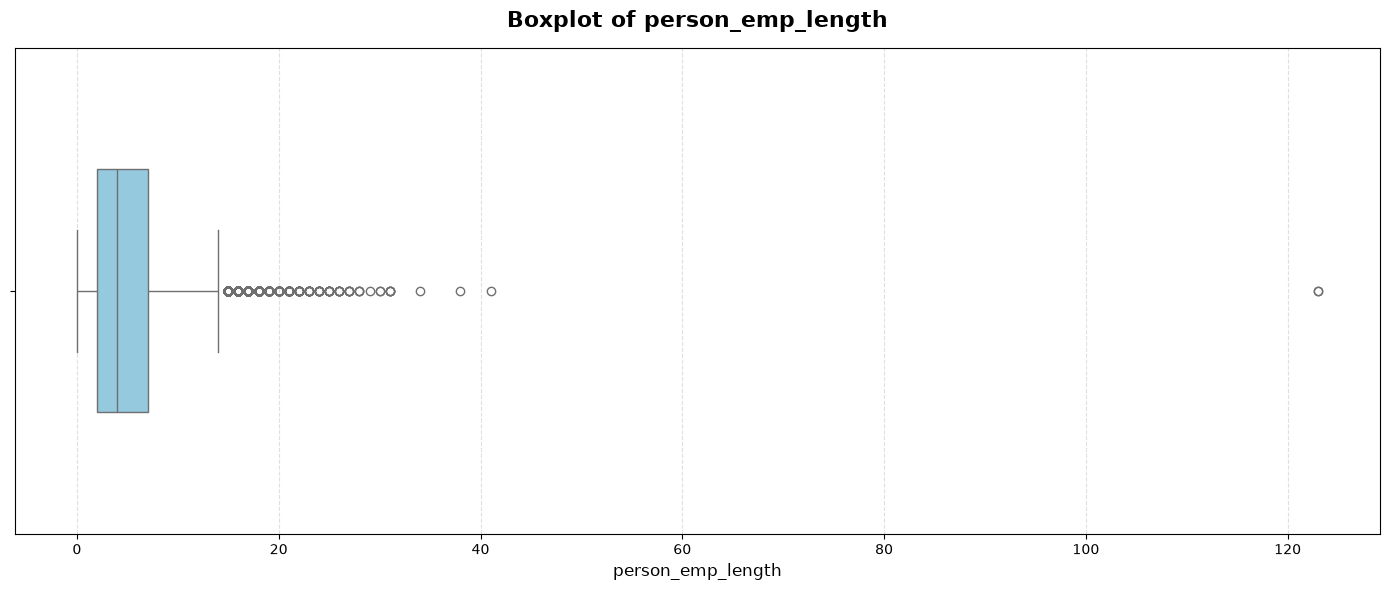

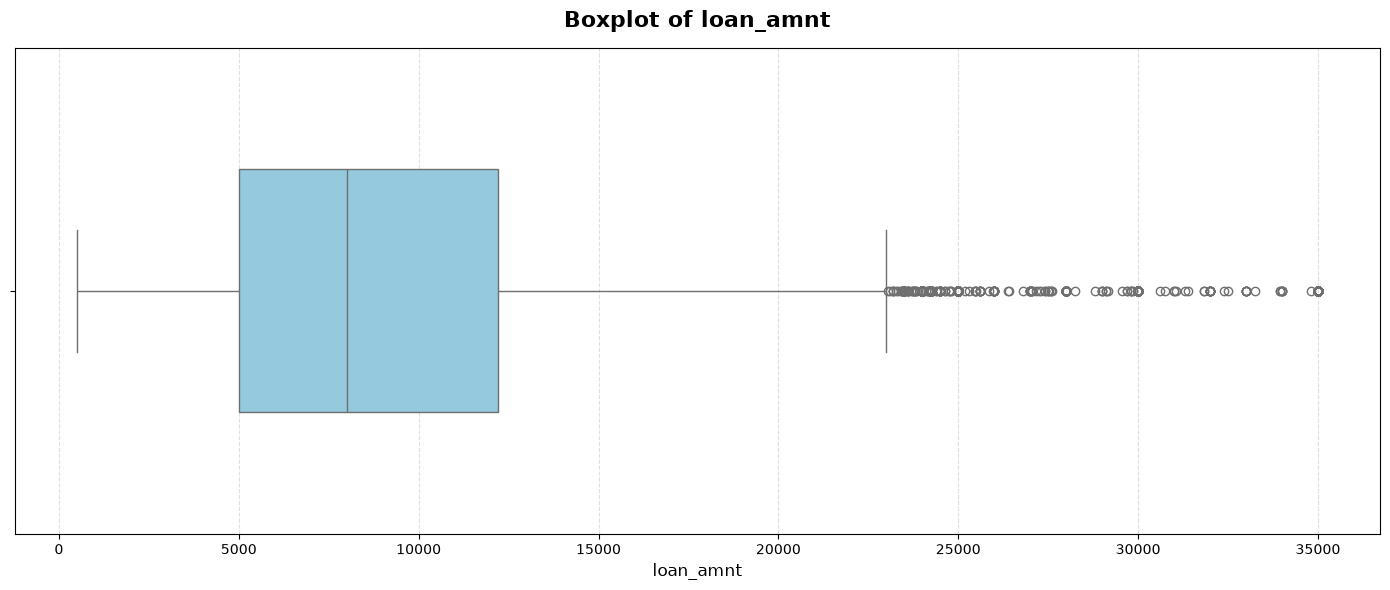

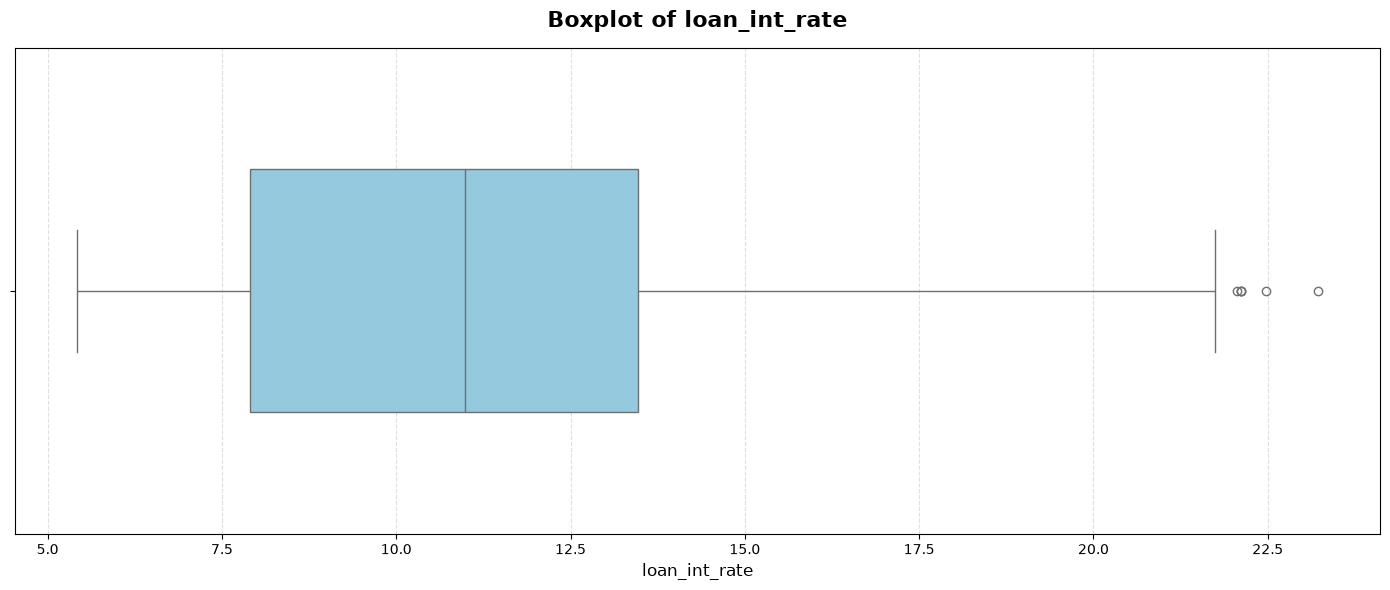

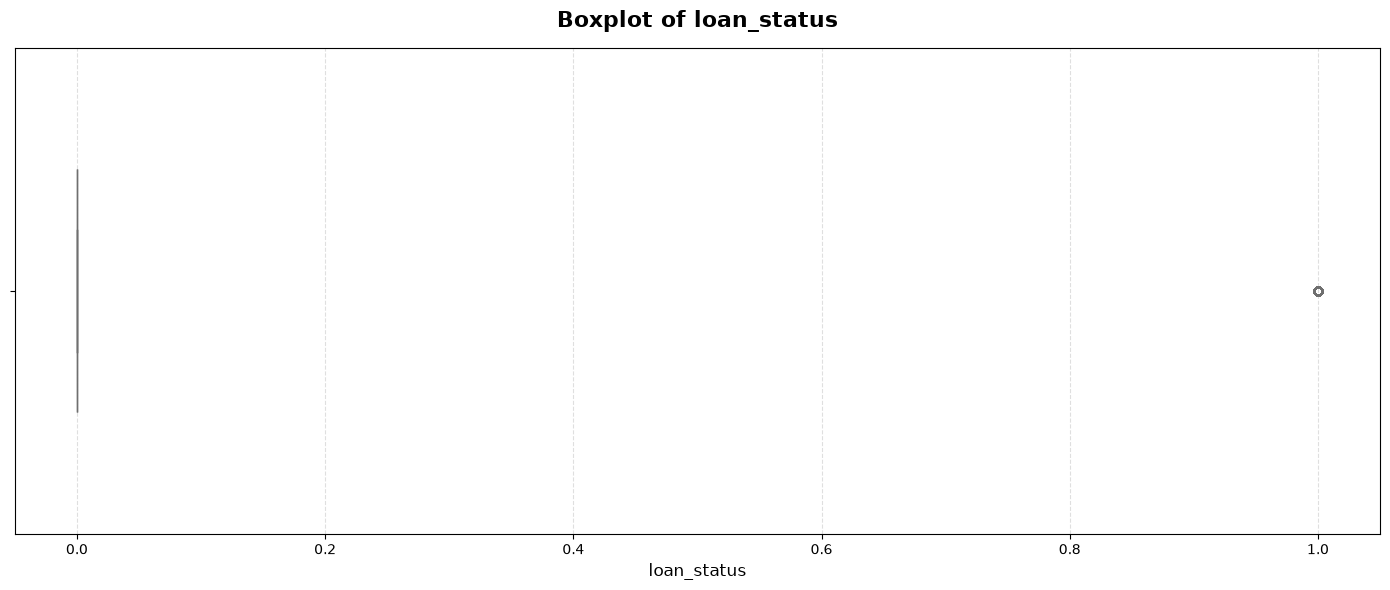

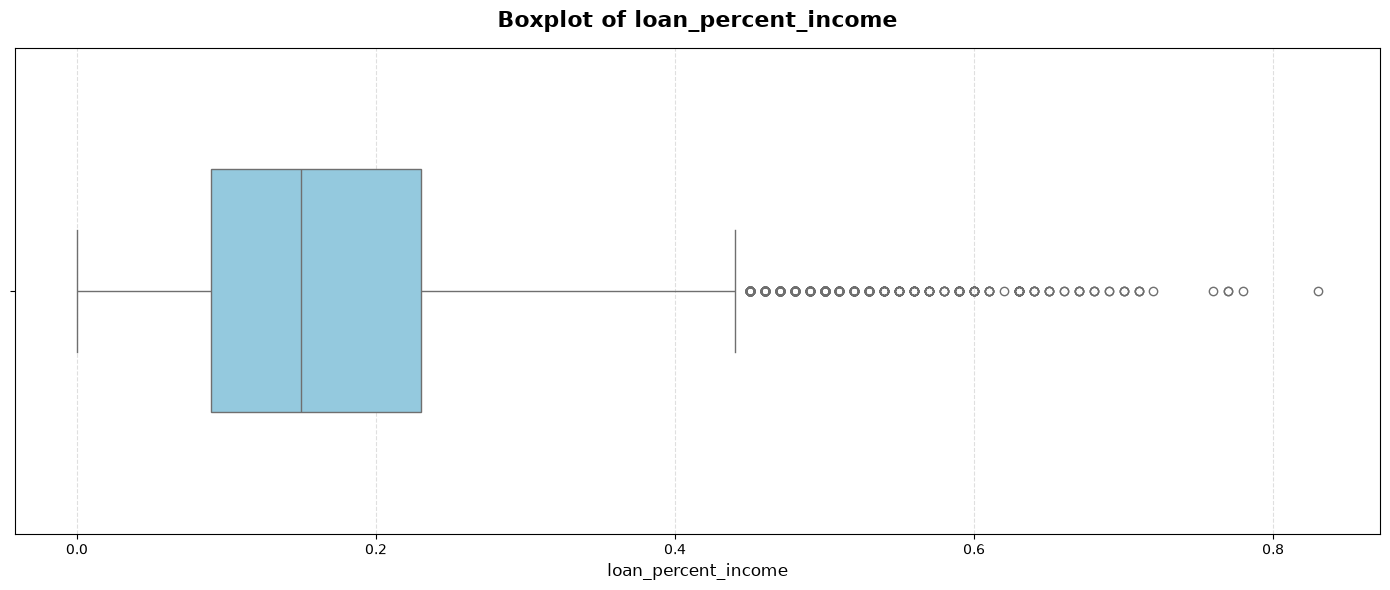

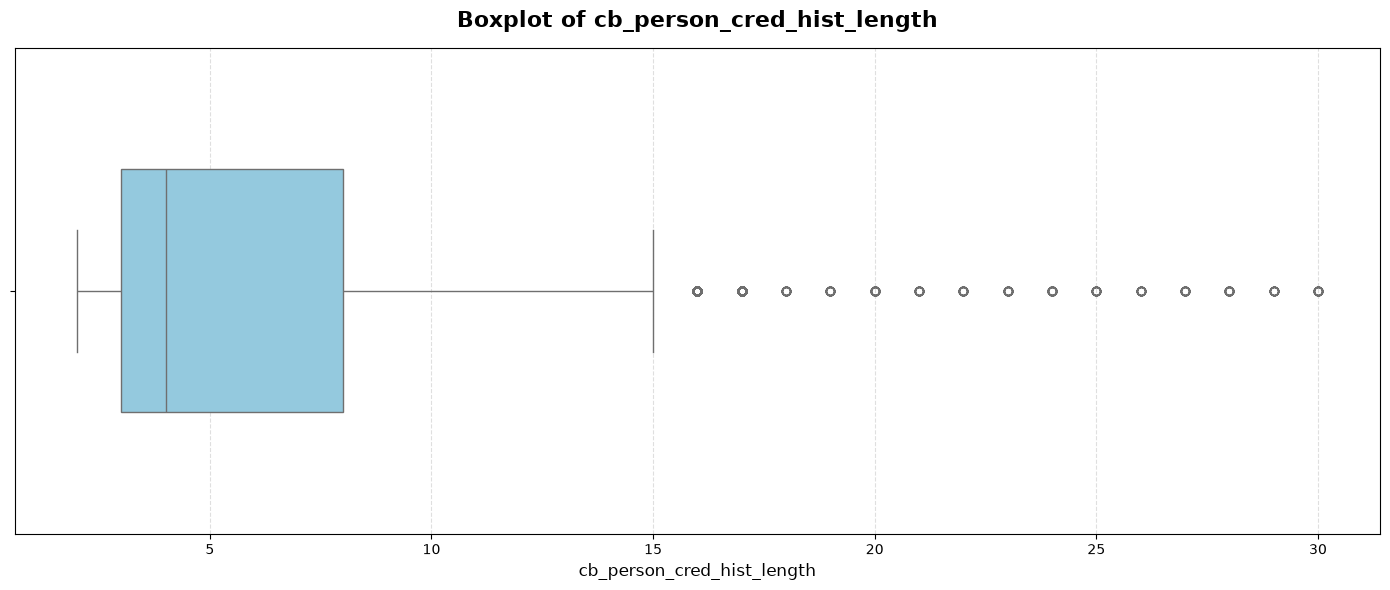

In [74]:
for col in numerical_cols:

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        x=df[col],
        color="skyblue",
        width=0.5
    )

    plt.title(f"Boxplot of {col}", fontsize=16, fontweight="bold", pad=15)
    plt.xlabel(col, fontsize=12)
    plt.grid(axis="x", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

In [75]:
print("Outliers - Person age: ",(df['person_age']>100).sum())

print("\nOutliers - Person emp length: ",(df['person_emp_length']>60).sum())

Outliers - Person age:  5

Outliers - Person emp length:  2


#### Correlation check

- See how features are related to each other
- This helps us spot repeated or linked information, gives us a pattern

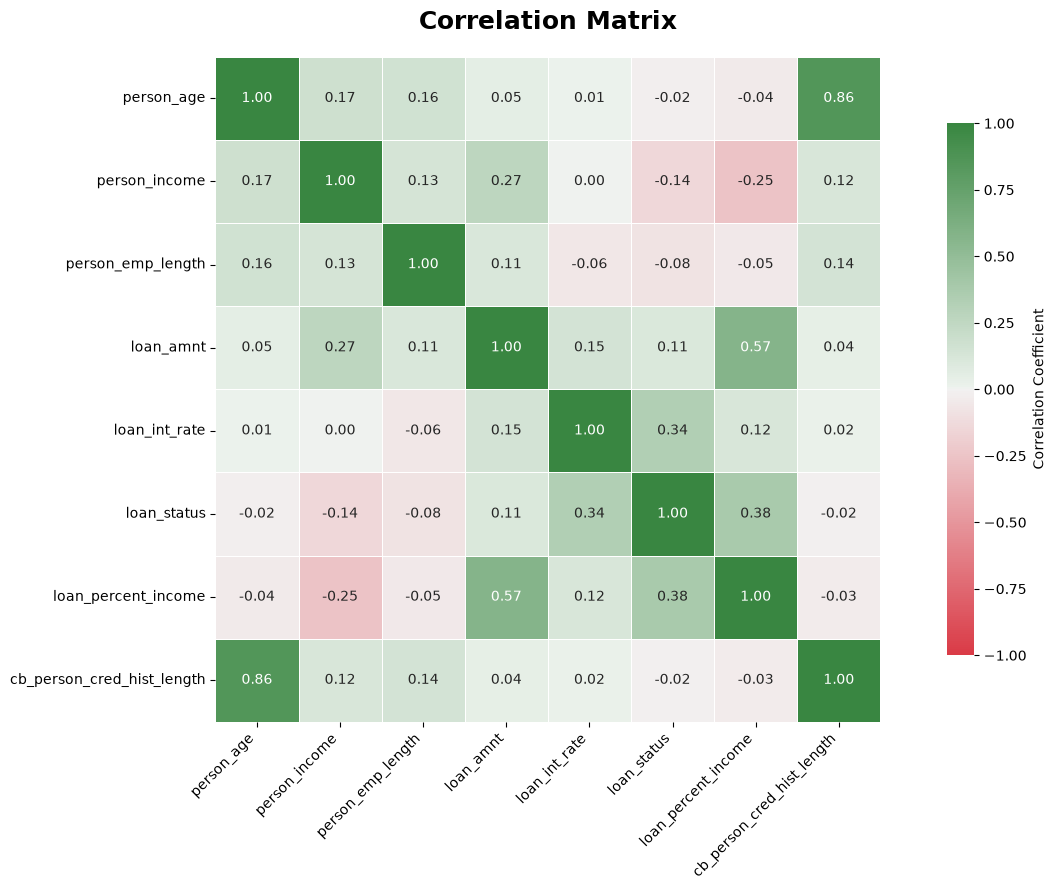

In [76]:
# Calculate correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Set figure dimensions
plt.figure(figsize=(14, 9))

# Create custom colormap
cmap = sns.diverging_palette(10, 130, as_cmap=True)

# Plot heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap=cmap,
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation Coefficient"
    }
)

plt.title(
    "Correlation Matrix",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

#### 3. Data Validation & Outlier Handling

- Clean the data properly.
- Remove duplicate rows.
- Remove outliers ( with impossible values (impossible age or work experience)).
- Remove rows with zero or negative income and loan amount.
- Check if the interest rate looks realistic.
- Flag the observations(rows) where numbers don't add up correctly.

In [77]:
df_copy = df.copy(deep = True)

# Remove duplicate rows

print(f"Number of observations before removing the duplicates: {df_copy.shape[0]}")
df_copy = df_copy.drop_duplicates()
print(f"\nNumber of observations after removing the duplicates: {df_copy.shape[0]}")

Number of observations before removing the duplicates: 32581

Number of observations after removing the duplicates: 32416


In [78]:
# Removing/Handling outliers -- 18 < Age > 100 and Employment length > Person's age

print(f"Number of observations before handling the outliers: {df_copy.shape[0]}")

# Removing outliers from age
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#Removing outliers from employment length
df_copy = df_copy[
    (df_copy['person_emp_length'] > 0) &
    (df_copy['person_emp_length'] < df_copy['person_age'])
]

# Remove the loan with zero or negative loan amounts
df_copy = df_copy[df_copy['loan_amnt'] > 0] # Notice in the description there are no negative loan amount


print(f"\nNumber of observations after removing the duplicates: {df_copy.shape[0]}")

Number of observations before handling the outliers: 32416

Number of observations after removing the duplicates: 27436


In [79]:
# Interest rate validation by loan intent

df['loan_intent'].unique().tolist() #Getting the types of loan intent for loan intent wise rate validation

['PERSONAL',
 'EDUCATION',
 'MEDICAL',
 'VENTURE',
 'HOMEIMPROVEMENT',
 'DEBTCONSOLIDATION']

In [80]:
# Annual interest rate screening ranges (%) -- according to current interest rates available in the market

interest_rate_ranges = {
    "PERSONAL": (5, 36),
    "EDUCATION": (3, 36),
    "MEDICAL": (0, 36),
    "VENTURE": (5, 40),
    "HOMEIMPROVEMENT": (5, 36),
    "DEBTCONSOLIDATION": (5, 36)
}

# Ensure consistent data types
df_copy["loan_int_rate"] = pd.to_numeric(
    df_copy["loan_int_rate"],
    errors="coerce"
)

df_copy["loan_intent"] = (
    df_copy["loan_intent"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Create a mask for unrealistic interest rates
unrealistic_mask = pd.Series(
    False,
    index=df_copy.index
)

for loan_intent, (min_rate, max_rate) in interest_rate_ranges.items():

    mask = (
        (df_copy["loan_intent"] == loan_intent) &
        (
            (df_copy["loan_int_rate"] < min_rate) |
            (df_copy["loan_int_rate"] > max_rate)
        )
    )

    unrealistic_mask |= mask


# Identify missing interest rates separately
missing_rate_mask = df_copy["loan_int_rate"].isna()

# Identify unknown loan intents
unknown_intent_mask = ~df_copy["loan_intent"].isin(
    interest_rate_ranges.keys()
)

# Loan-intent-wise analysis

summary = pd.DataFrame(index=interest_rate_ranges.keys())

summary.index.name = "Loan Intent"

# Total observations per loan intent
summary["Total Observations"] = (
    df_copy["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Unrealistic observations
summary["Unrealistic Observations"] = (
    df_copy.loc[unrealistic_mask]
    ["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Missing interest rates
summary["Missing Interest Rates"] = (
    df_copy.loc[missing_rate_mask]
    ["loan_intent"]
    .value_counts()
    .reindex(summary.index, fill_value=0)
)

# Percentage of unrealistic observations
summary["Unrealistic Percentage"] = (
    summary["Unrealistic Observations"] /
    summary["Total Observations"].replace(0, np.nan) * 100
).round(2)

display(summary)


# Overall cleaning summary

total_observations = len(df_copy)
unrealistic_count = int(unrealistic_mask.sum())
missing_count = int(missing_rate_mask.sum())
unknown_count = int(unknown_intent_mask.sum())

print("\n========== INTEREST RATE VALIDATION SUMMARY ==========")

print(f"Total observations:                 {total_observations:,}")
print(f"Unrealistic interest rates:         {unrealistic_count:,}")
print(f"Missing interest rates:             {missing_count:,}")
print(f"Unknown loan intents:               {unknown_count:,}")

print(
    f"Percentage of unrealistic rates:   "
    f"{unrealistic_count / total_observations * 100:.2f}%"
    if total_observations else
    "Percentage of unrealistic rates: 0.00%"
)

print(
    f"Potential rows to remove:           {unrealistic_count:,}"
)

print(
    f"Observations remaining:             "
    f"{total_observations - unrealistic_count:,}"
)


# Inspect observations before removal - currently commenting the code since there are no unrealisitic interest rates

# display(
#     df_copy.loc[
#         unrealistic_mask,
#         [
#             "person_age",
#             "person_income",
#             "loan_intent",
#             "loan_grade",
#             "loan_amnt",
#             "loan_int_rate",
#             "loan_status"
#         ]
#     ].sort_values(
#         "loan_int_rate",
#         ascending=False
#     )
# )

,Total Observations,Unrealistic Observations,Missing Interest Rates,Unrealistic Percentage
Loan Intent,,,,
PERSONAL,4670,0,427,0.0
EDUCATION,5418,0,505,0.0
MEDICAL,5097,0,521,0.0
VENTURE,4829,0,474,0.0
HOMEIMPROVEMENT,3052,0,280,0.0
DEBTCONSOLIDATION,4370,0,424,0.0



========== INTEREST RATE VALIDATION SUMMARY ==========
Total observations:                 27,436
Unrealistic interest rates:         0
Missing interest rates:             2,631
Unknown loan intents:               0
Percentage of unrealistic rates:   0.00%
Potential rows to remove:           0
Observations remaining:             27,436
